# PCOS Dataset Analysis

This notebook explores a PCOS (Polycystic Ovary Syndrome) dataset with 541 patients and looks at which
features are related to the `PCOS (Y/N)` target. The plan is to go through the data step by step: check
data quality, look at individual features, check correlations and multicollinearity, compare a few
feature-importance methods, and end with a feature list that seems reasonable for a Random Forest / XGBoost
model.

Contents:
1. Dataset Overview
2. Data Cleaning
3. Target Variable
4. Univariate Analysis
5. Feature vs Target Analysis
6. Correlation and Multicollinearity
7. Multivariate Analysis
8. Feature Importance
9. Bias and Leakage Check
10. Feature Engineering
11. Feature Ranking
12. Conclusion


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pointbiserialr, mannwhitneyu, chi2_contingency

from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

import xgboost as xgb

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False

pd.set_option('display.max_columns', 100)
RANDOM_STATE = 42

## 1. Dataset Overview

In [2]:
df = pd.read_csv('augmented_pcos.csv')
df.columns = df.columns.str.strip()
print(df.shape)
df.head()

(1932, 42)


,Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),Cycle length(days),Marraige Status (Yrs),Pregnant(Y/N),No. of aborptions,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),FSH(mIU/mL),LH(mIU/mL),FSH/LH,Hip(inch),Waist(inch),Waist:Hip Ratio,TSH (mIU/L),AMH(ng/mL),PRL(ng/mL),Vit D3 (ng/mL),PRG(ng/mL),RBS(mg/dl),Weight gain(Y/N),hair growth(Y/N),Skin darkening (Y/N),Hair loss(Y/N),Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),PCOS (Y/N)
0,31,55.3,159.799,23.022600,15,72,18,10.42,2,5,3.2,0,0,74.570,0.990,4.256,0.590,6.243748,43,35,0.902532,1.808,2.818,4.88,30.642,0.230,90.7,0,0,0,0,0,0.0,0,110,80,3,11,18.1,16.08,5.63,0
1,35,66.8,157.808,24.641938,15,72,18,10.66,2,5,8.7,0,0,295.145,0.990,5.380,1.782,4.365691,39,42,0.928757,1.466,1.255,16.75,33.966,0.433,112.3,0,0,0,0,0,1.0,0,120,80,3,2,19.5,20.44,4.14,0
2,37,63.5,154.713,23.886189,15,72,18,10.98,2,5,6.7,0,0,323.157,0.990,5.192,3.349,1.265747,38,36,0.944058,2.885,1.365,21.64,30.991,0.198,95.0,0,0,0,0,0,0.0,0,120,80,3,0,14.2,18.84,8.84,0
3,32,56.6,151.987,30.392813,15,72,18,11.20,2,5,4.2,0,0,1.300,58.607,5.326,3.418,3.193229,42,36,0.873273,1.345,1.038,13.03,35.505,0.437,100.6,1,0,0,0,1,1.0,0,110,80,4,13,12.0,11.26,9.63,0
4,30,55.0,162.000,20.957171,12,72,18,11.20,2,6,10.0,0,0,4.600,2.800,6.060,3.790,1.598945,37,35,0.945946,2.260,3.020,30.71,48.630,0.410,91.0,0,0,0,1,1,1.0,1,120,70,5,6,12.0,15.00,8.50,0


No ID or index column is in this file, so nothing needs to be dropped for that reason.

In [3]:
id_like = [c for c in df.columns if df[c].nunique() == len(df)]
id_like

[]

In [4]:
df.dtypes

Age (yrs)                   int64
Weight (Kg)               float64
Height(Cm)                float64
BMI                       float64
Blood Group                 int64
Pulse rate(bpm)             int64
RR (breaths/min)            int64
Hb(g/dl)                  float64
Cycle(R/I)                  int64
Cycle length(days)          int64
Marraige Status (Yrs)     float64
Pregnant(Y/N)               int64
No. of aborptions           int64
I   beta-HCG(mIU/mL)      float64
II    beta-HCG(mIU/mL)    float64
FSH(mIU/mL)               float64
LH(mIU/mL)                float64
FSH/LH                    float64
Hip(inch)                   int64
Waist(inch)                 int64
Waist:Hip Ratio           float64
TSH (mIU/L)               float64
AMH(ng/mL)                float64
PRL(ng/mL)                float64
Vit D3 (ng/mL)            float64
PRG(ng/mL)                float64
RBS(mg/dl)                float64
Weight gain(Y/N)            int64
hair growth(Y/N)            int64
Skin darkening


Most columns are already numeric. The target is `PCOS (Y/N)` (0/1). Some columns are really
categorical even though they're stored as numbers, e.g. `Blood Group` and `Cycle(R/I)`. There's a group of
Y/N symptom columns (`hair growth`, `Skin darkening`, `Weight gain`, `Hair loss`, `Pimples`, `Fast food`,
`Reg.Exercise`, `Pregnant`), and the rest are continuous clinical/hormonal measurements.


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age (yrs),1932.0,31.196687,5.371312,20.000000,27.000000,31.000000,35.000000,48.000000
Weight (Kg),1932.0,58.834731,9.282896,31.000000,53.300000,58.700000,64.200000,108.000000
Height(Cm),1932.0,156.336928,5.468051,137.000000,152.039500,156.149500,160.287250,180.000000
BMI,1932.0,24.854938,4.070335,12.417882,22.132099,24.600000,27.645856,38.900000
Blood Group,1932.0,14.414596,1.318495,11.000000,15.000000,15.000000,15.000000,18.000000
Pulse rate(bpm),1932.0,72.486542,2.450615,13.000000,72.000000,72.000000,72.000000,82.000000
RR (breaths/min),1932.0,18.656832,1.151290,16.000000,18.000000,18.000000,20.000000,28.000000
Hb(g/dl),1932.0,10.818794,0.592917,9.000000,10.440000,10.790000,11.100000,14.800000
Cycle(R/I),1932.0,2.428054,0.821450,2.000000,2.000000,2.000000,2.000000,5.000000
Cycle length(days),1932.0,4.807453,1.055766,0.000000,5.000000,5.000000,5.000000,12.000000


## 2. Data Cleaning

### Missing values and duplicates

In [6]:
df.isnull().sum().sum()

np.int64(0)

There are no NaNs in this file. That doesn't mean everything is clean though — a few columns use placeholder numbers instead of real NaNs, which is checked below.

In [7]:
df.duplicated().sum()

np.int64(0)

### Checking for suspicious values

In [8]:
(df['I   beta-HCG(mIU/mL)'] == 1.99).sum(), (df['II    beta-HCG(mIU/mL)'] == 1.99).sum()

(np.int64(158), np.int64(252))

A lot of rows have exactly `1.99` for beta-HCG, which looks like a placeholder for "test not done" rather than an actual measurement. Worth keeping in mind since it will pull the distribution and any correlation involving this column toward that fixed value.

In [9]:
df['Cycle(R/I)'].value_counts()

Cycle(R/I)
2    1519
4     412
5       1
Name: count, dtype: int64

`Cycle(R/I)` should only be 2 (regular) or 4 (irregular), but there's a single row with value 5. Looks like a typo in the original data rather than a real third category.

In [10]:
df[['Pulse rate(bpm)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Vit D3 (ng/mL)', 'FSH(mIU/mL)']].describe().loc[['min','max']]

,Pulse rate(bpm),BP _Systolic (mmHg),BP _Diastolic (mmHg),Vit D3 (ng/mL),FSH(mIU/mL)
min,13.0,12.0,8.0,6.077,0.21
max,82.0,140.0,100.0,6014.660,5052.00



A pulse rate of 13 bpm and a systolic BP of 12 mmHg aren't realistic for a living patient, so those are
almost certainly data-entry errors. `Vit D3` going up to ~6000 ng/mL and `FSH` up to ~5000 mIU/mL are also
way outside plausible ranges. None of these are dropped here since fixing them properly would mean
guessing the correct value — but they should be cleaned up (capped or set to NaN and imputed) before this
data goes into a real model, since they can distort correlations and outlier statistics.


In [11]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
flag_cols = ['PCOS (Y/N)', 'Pregnant(Y/N)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)',
             'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'Cycle(R/I)', 'Blood Group']
continuous_cols = [c for c in numeric_cols if c not in flag_cols]

q1 = df[continuous_cols].quantile(0.25)
q3 = df[continuous_cols].quantile(0.75)
iqr = q3 - q1
outlier_count = ((df[continuous_cols] < (q1 - 1.5*iqr)) | (df[continuous_cols] > (q3 + 1.5*iqr))).sum()
outlier_count.sort_values(ascending=False).head(10)

Cycle length(days)        510
Pulse rate(bpm)           377
AMH(ng/mL)                244
BP _Diastolic (mmHg)      168
RBS(mg/dl)                145
Hip(inch)                 127
II    beta-HCG(mIU/mL)    122
TSH (mIU/L)                98
No. of aborptions          87
Hb(g/dl)                   74
dtype: int64

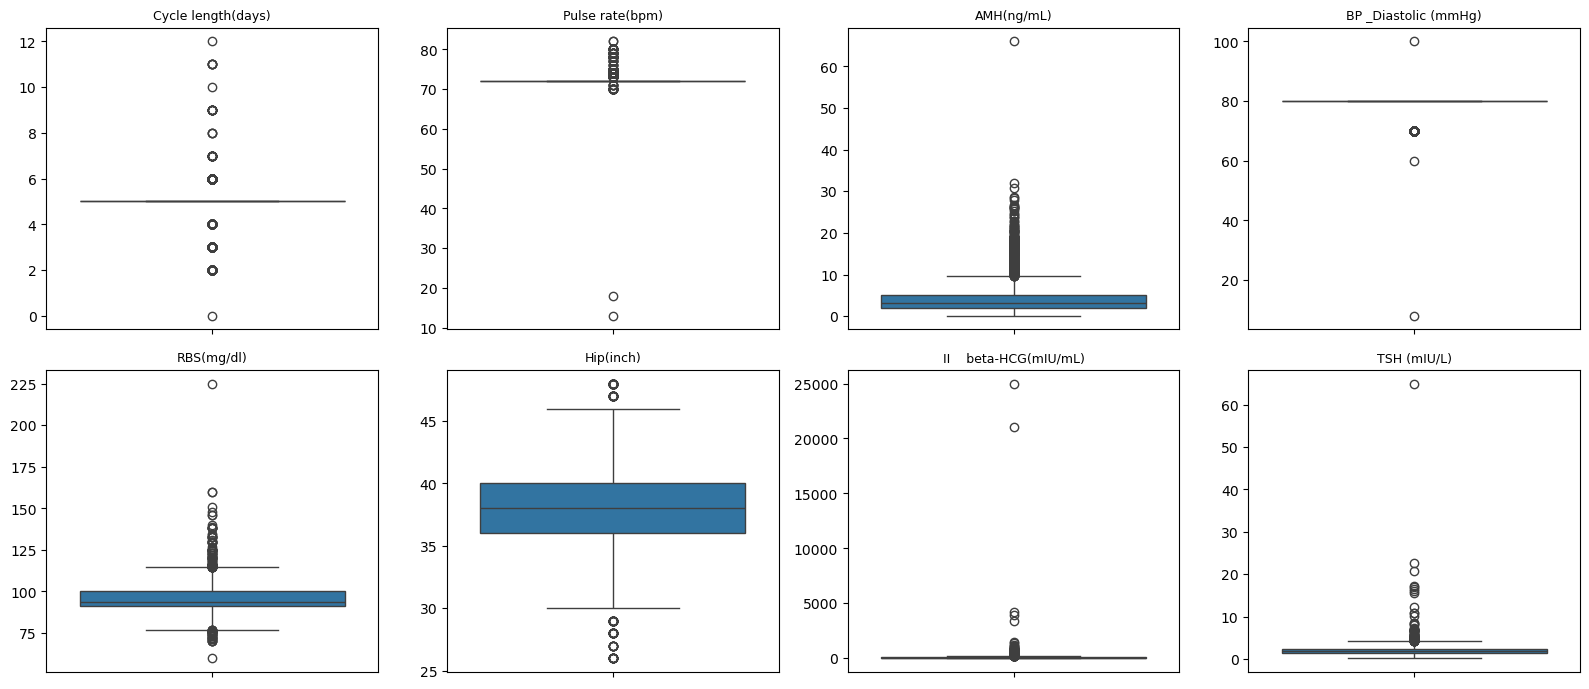

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flatten(), outlier_count.sort_values(ascending=False).head(8).index):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c, fontsize=9)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()


The hormone-related columns (`FSH/LH`, `LH`, `FSH`, `AMH`, beta-HCG) have the most outliers by the IQR rule.
Some of that is expected — PCOS patients really can have unusually high LH/FSH ratios and AMH, so these
aren't automatically errors. The ones flagged above as physiologically impossible (pulse rate, blood
pressure) are a different story and are more likely mistakes than real biology.


## 3. Target Variable

The target column is `PCOS (Y/N)`: 0 for no PCOS, 1 for PCOS.

In [13]:
target = 'PCOS (Y/N)'
df[target].value_counts()

PCOS (Y/N)
0    1299
1     633
Name: count, dtype: int64

In [14]:
df[target].value_counts(normalize=True) * 100

PCOS (Y/N)
0    67.236025
1    32.763975
Name: proportion, dtype: float64

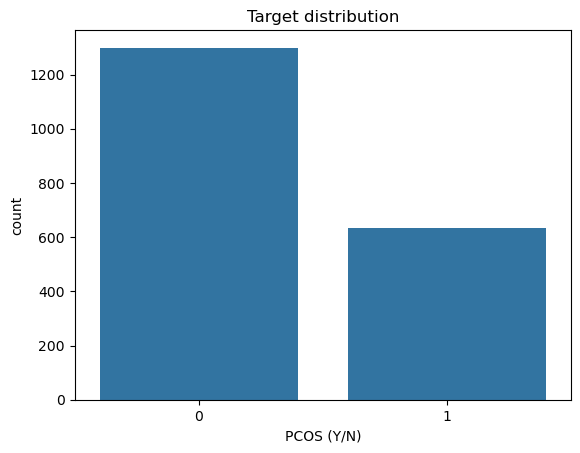

In [15]:
sns.countplot(x=df[target])
plt.title('Target distribution')
plt.show()


About two-thirds of the patients don't have PCOS and one-third do, so the classes aren't balanced 50/50.
It's not an extreme imbalance, but accuracy alone would be a misleading metric here — a model that always
predicts "no PCOS" would already get ~67% accuracy. Precision/recall per class, ROC-AUC, and PR-AUC are
better ways to judge the model, and it's worth using `class_weight='balanced'` (Random Forest) or
`scale_pos_weight` (XGBoost) when training.


## 4. Univariate Analysis

### Numerical features

In [16]:
summary = df[continuous_cols].agg(['mean', 'median', 'std', 'min', 'max']).T
summary['skew'] = df[continuous_cols].skew()
summary.sort_values('skew', ascending=False).round(2)

,mean,median,std,min,max,skew
FSH(mIU/mL),7.16,4.38,114.88,0.21,5052.00,43.91
FSH/LH,3.81,2.42,32.16,0.23,1372.83,40.52
PRG(ng/mL),0.36,0.33,0.61,0.05,25.30,36.35
Vit D3 (ng/mL),35.27,28.50,183.59,6.08,6014.66,30.98
II beta-HCG(mIU/mL),86.47,13.98,766.62,0.99,25000.00,28.65
I beta-HCG(mIU/mL),246.02,102.47,1447.73,1.30,30007.00,17.21
TSH (mIU/L),2.07,1.79,2.08,0.22,65.00,16.37
No. of aborptions,0.06,0.00,0.34,0.00,5.00,6.77
AMH(ng/mL),4.74,3.07,5.07,0.10,66.00,2.87
LH(mIU/mL),2.38,2.25,1.80,0.03,14.69,2.02


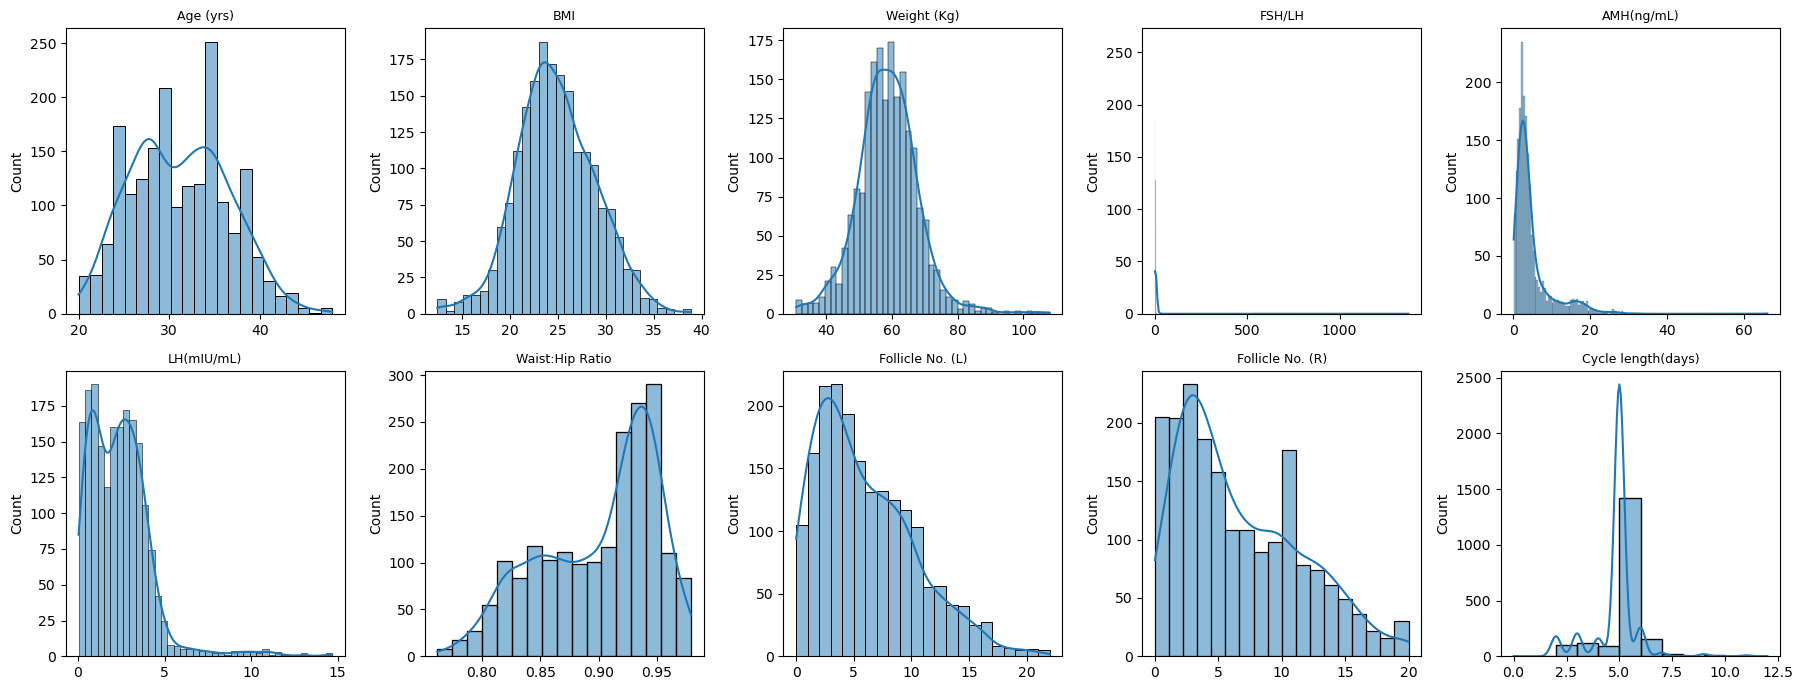

In [17]:
key_numeric = ['Age (yrs)', 'BMI', 'Weight (Kg)', 'FSH/LH', 'AMH(ng/mL)', 'LH(mIU/mL)',
               'Waist:Hip Ratio', 'Follicle No. (L)', 'Follicle No. (R)', 'Cycle length(days)']

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, c in zip(axes.flatten(), key_numeric):
    sns.histplot(df[c], kde=True, ax=ax)
    ax.set_title(c, fontsize=9)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()


The hormone-related columns (`FSH/LH`, `AMH`, beta-HCG, `PRL`, `TSH`) are all heavily right-skewed, which
makes sense for hormone assay data. Age, Hb, and blood pressure look roughly normal. `Follicle No.` shows
a wider spread which is a hint it might separate the two classes well — checked properly in the next
section.


### Categorical / binary features

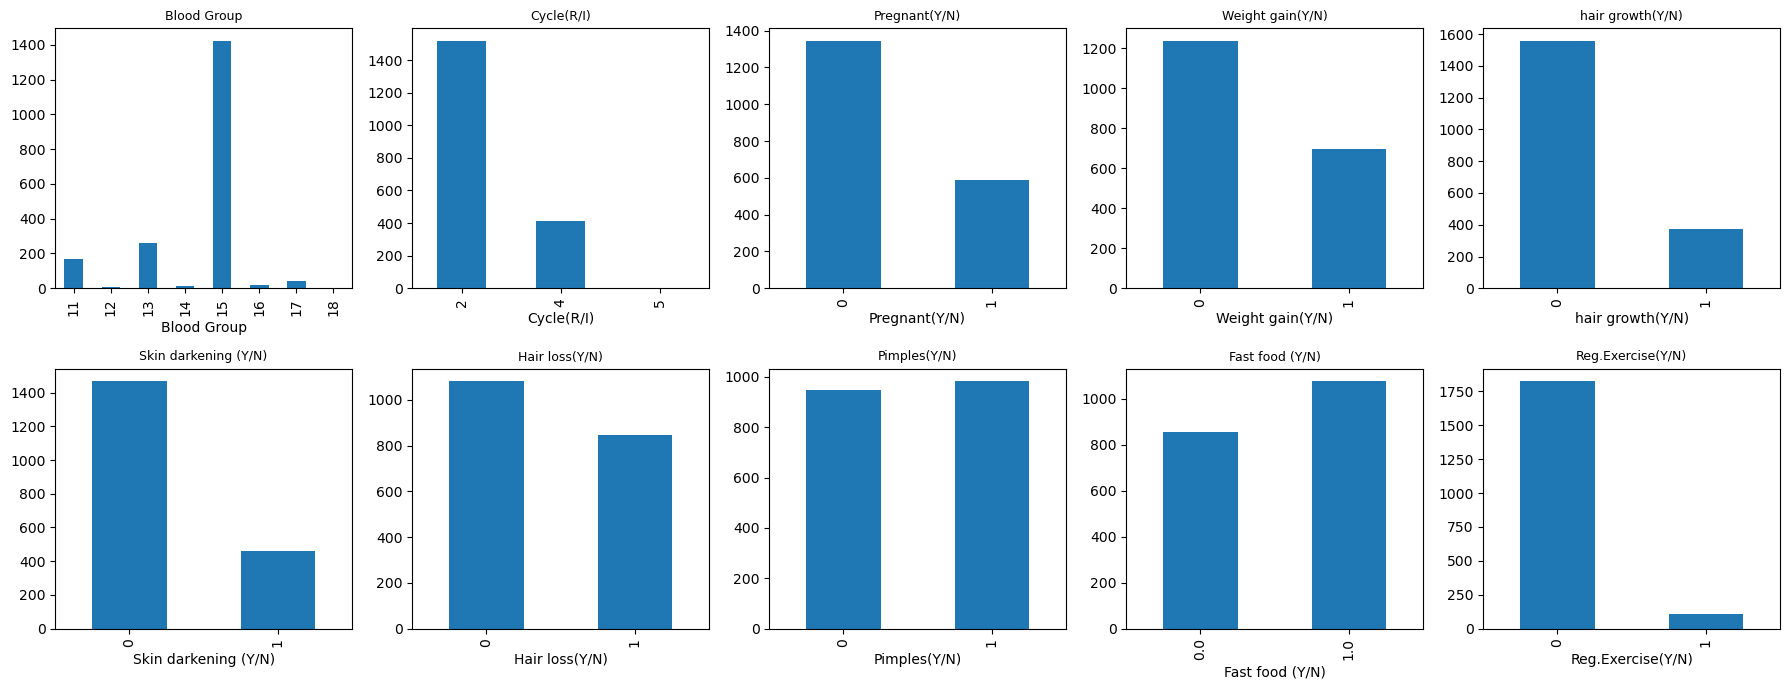

In [18]:
categorical_cols = ['Blood Group', 'Cycle(R/I)', 'Pregnant(Y/N)', 'Weight gain(Y/N)', 'hair growth(Y/N)',
                     'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)',
                     'Reg.Exercise(Y/N)']

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, c in zip(axes.flatten(), categorical_cols):
    df[c].value_counts().sort_index().plot(kind='bar', ax=ax)
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()


Most of the symptom flags (`hair growth`, `Skin darkening`, `Pimples`, `Weight gain`, `Hair loss`) have a
reasonably even 0/1 split, which is good for finding a relationship with the target later. `Blood Group`
is spread fairly evenly across its 8 codes and doesn't have an obvious reason to matter medically for
PCOS — coming back to this in the bias/leakage section.


## 5. Feature vs Target Analysis

### Numerical features

In [19]:
rows = []
for c in continuous_cols:
    g0 = df.loc[df[target] == 0, c]
    g1 = df.loc[df[target] == 1, c]
    r, p = pointbiserialr(df[target], df[c])
    _, p_mw = mannwhitneyu(g0, g1)
    rows.append([c, r, p, p_mw, g0.mean(), g1.mean()])

num_vs_target = pd.DataFrame(rows, columns=['feature', 'point_biserial_r', 'p_value', 'p_value_mannwhitney',
                                             'mean_no_pcos', 'mean_pcos'])
num_vs_target['abs_r'] = num_vs_target['point_biserial_r'].abs()
num_vs_target = num_vs_target.sort_values('abs_r', ascending=False).reset_index(drop=True)
num_vs_target.round(4)

,feature,point_biserial_r,p_value,p_value_mannwhitney,mean_no_pcos,mean_pcos,abs_r
0,Follicle No. (R),0.6694,0.0000,0.0000,4.4450,11.2970,0.6694
1,Follicle No. (L),0.6165,0.0000,0.0000,4.0346,9.6524,0.6165
2,AMH(ng/mL),0.4549,0.0000,0.0000,3.1294,8.0423,0.4549
3,Cycle length(days),-0.3679,0.0000,0.0000,5.0785,4.2512,0.3679
4,Age (yrs),-0.3040,0.0000,0.0000,32.3364,28.8578,0.3040
5,Waist(inch),0.2364,0.0000,0.0000,33.5173,35.2686,0.2364
6,Weight (Kg),0.2247,0.0000,0.0000,57.3793,61.8215,0.2247
7,BMI,0.2236,0.0000,0.0000,24.2198,26.1584,0.2236
8,Hip(inch),0.2215,0.0000,0.0000,37.3372,39.2970,0.2215
9,Marraige Status (Yrs),-0.2075,0.0000,0.0000,8.0503,6.1081,0.2075


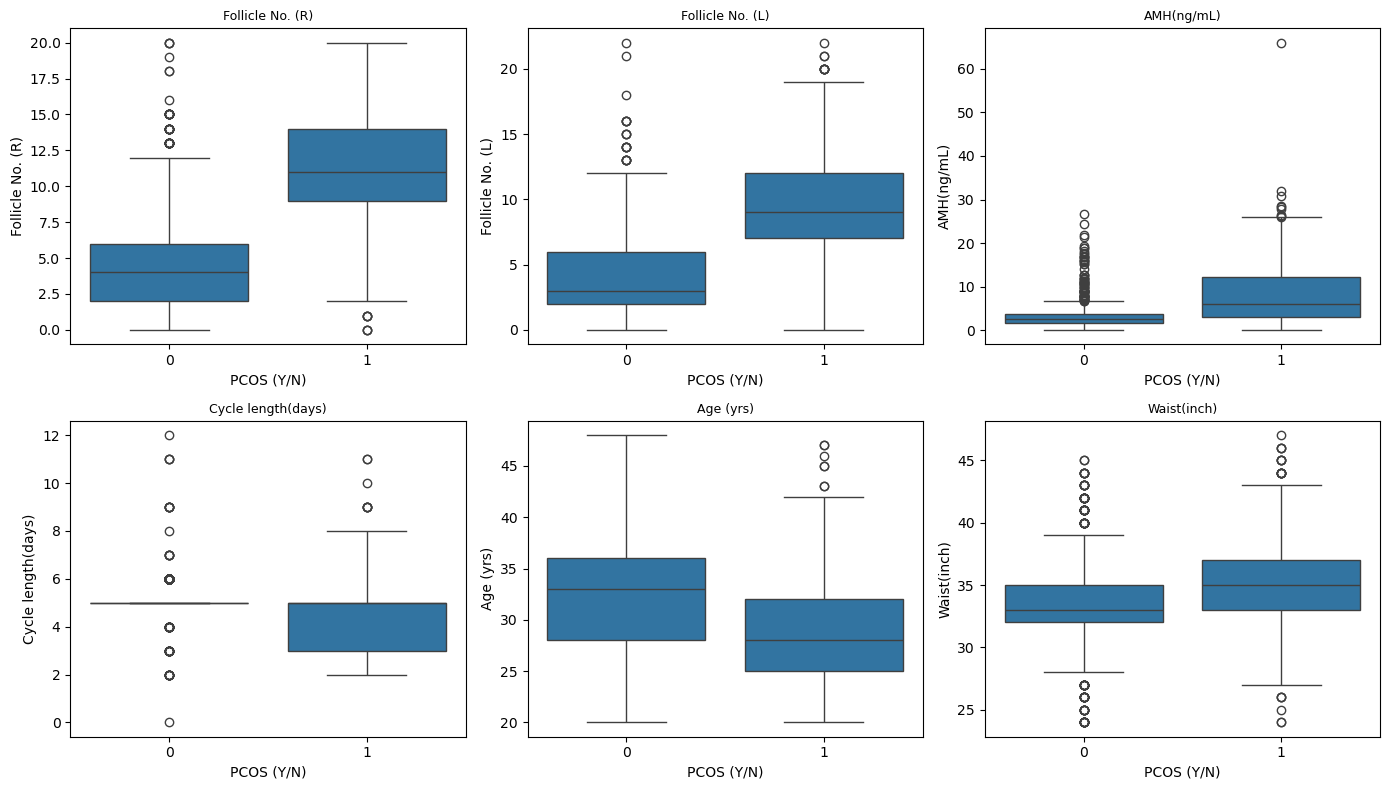

In [20]:
top_num = num_vs_target.head(6)['feature'].tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flatten(), top_num):
    sns.boxplot(x=df[target], y=df[c], ax=ax)
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()


`Follicle No.` on both sides, `Skin darkening`-related hormones, and `Waist:Hip Ratio` show the clearest
separation between the two groups. All the p-values here are very small, but with ~540 rows even fairly
small correlations can be statistically significant, so the actual size of the correlation (and the
boxplot) matters more than just the p-value when judging usefulness for a model.


### Categorical features

In [21]:
rows = []
for c in categorical_cols:
    table = pd.crosstab(df[c], df[target])
    chi2, p, dof, exp = chi2_contingency(table)
    n = table.sum().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    rows.append([c, chi2, p, cramers_v])

cat_vs_target = pd.DataFrame(rows, columns=['feature', 'chi2', 'p_value', 'cramers_v'])
cat_vs_target = cat_vs_target.sort_values('cramers_v', ascending=False).reset_index(drop=True)
cat_vs_target.round(4)

,feature,chi2,p_value,cramers_v
0,Skin darkening (Y/N),830.6126,0.0000,0.6557
1,hair growth(Y/N),638.4792,0.0000,0.5749
2,Cycle(R/I),574.4556,0.0000,0.5453
3,Fast food (Y/N),505.2847,0.0000,0.5114
4,Weight gain(Y/N),488.3266,0.0000,0.5027
5,Pimples(Y/N),407.1548,0.0000,0.4591
6,Hair loss(Y/N),227.1929,0.0000,0.3429
7,Blood Group,29.9951,0.0001,0.1246
8,Reg.Exercise(Y/N),1.5086,0.2193,0.0279
9,Pregnant(Y/N),0.7425,0.3889,0.0196


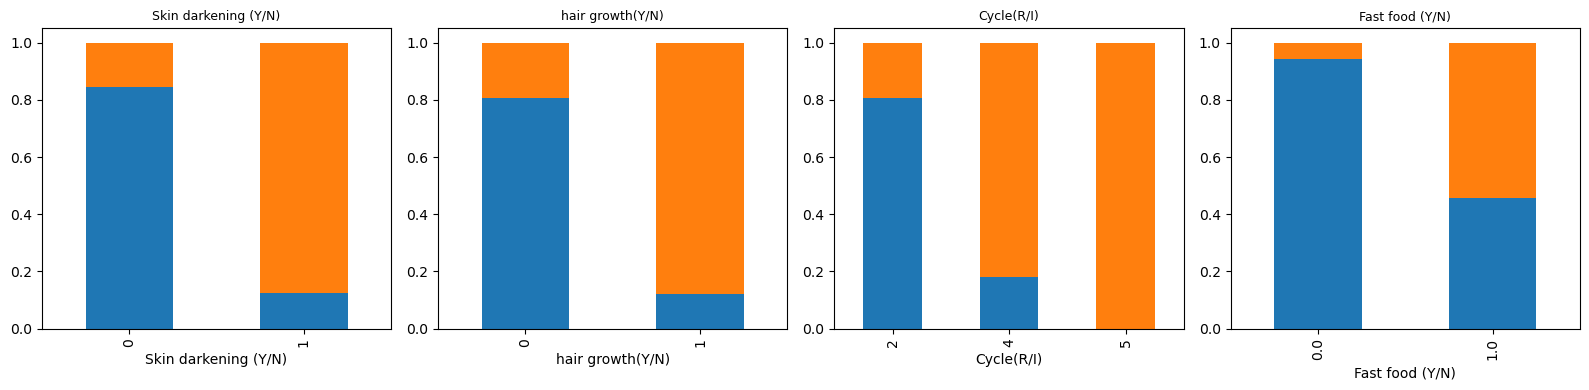

In [22]:
top_cat = cat_vs_target.head(4)['feature'].tolist()
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, top_cat):
    pd.crosstab(df[c], df[target], normalize='index').plot(kind='bar', stacked=True, ax=ax, legend=False)
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()


`Skin darkening`, `hair growth`, and `Weight gain` show the strongest association with the target among
the categorical features, using Cramér's V. That lines up with what's known clinically — these are
hyperandrogenism symptoms that are part of how PCOS gets diagnosed in the first place, which is something
to flag later in the leakage discussion.


## 6. Correlation and Multicollinearity

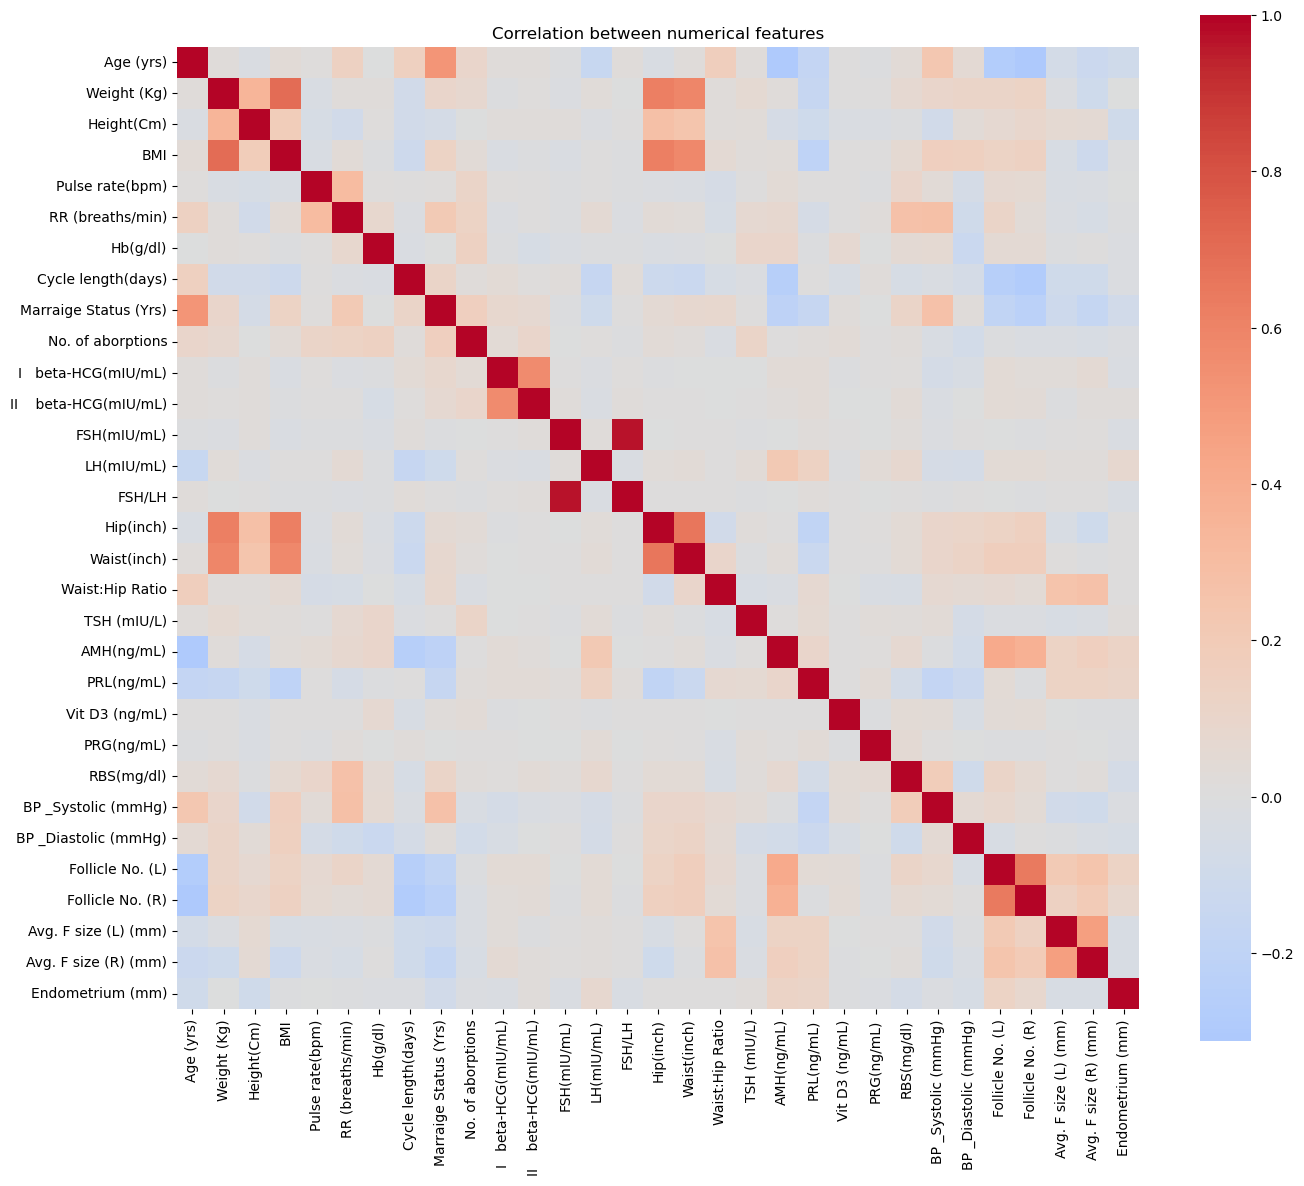

In [23]:
corr = df[continuous_cols].corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True)
plt.title('Correlation between numerical features')
plt.tight_layout()
plt.show()

In [24]:
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index()
pairs.columns = ['feature_1', 'feature_2', 'r']
pairs['abs_r'] = pairs['r'].abs()
pairs.sort_values('abs_r', ascending=False).head(10)

,feature_1,feature_2,r,abs_r
295,FSH(mIU/mL),FSH/LH,0.971511,0.971511
31,Weight (Kg),BMI,0.697590,0.697590
345,Hip(inch),Waist(inch),0.660064,0.660064
455,Follicle No. (L),Follicle No. (R),0.643677,0.643677
43,Weight (Kg),Hip(inch),0.621824,0.621824
98,BMI,Hip(inch),0.620586,0.620586
44,Weight (Kg),Waist(inch),0.591213,0.591213
99,BMI,Waist(inch),0.579736,0.579736
255,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),0.566423,0.566423
7,Age (yrs),Marraige Status (Yrs),0.522801,0.522801



The strongest correlated pairs are exactly what you'd expect from how some of these columns are built:
`Weight` and `BMI`, `Hip`/`Waist` and `Waist:Hip Ratio`, `FSH`/`LH` and `FSH/LH`, and the two beta-HCG
readings. These pairs carry overlapping information, so keeping all of them isn't adding much for a
linear model, though it doesn't hurt Random Forest / XGBoost much.


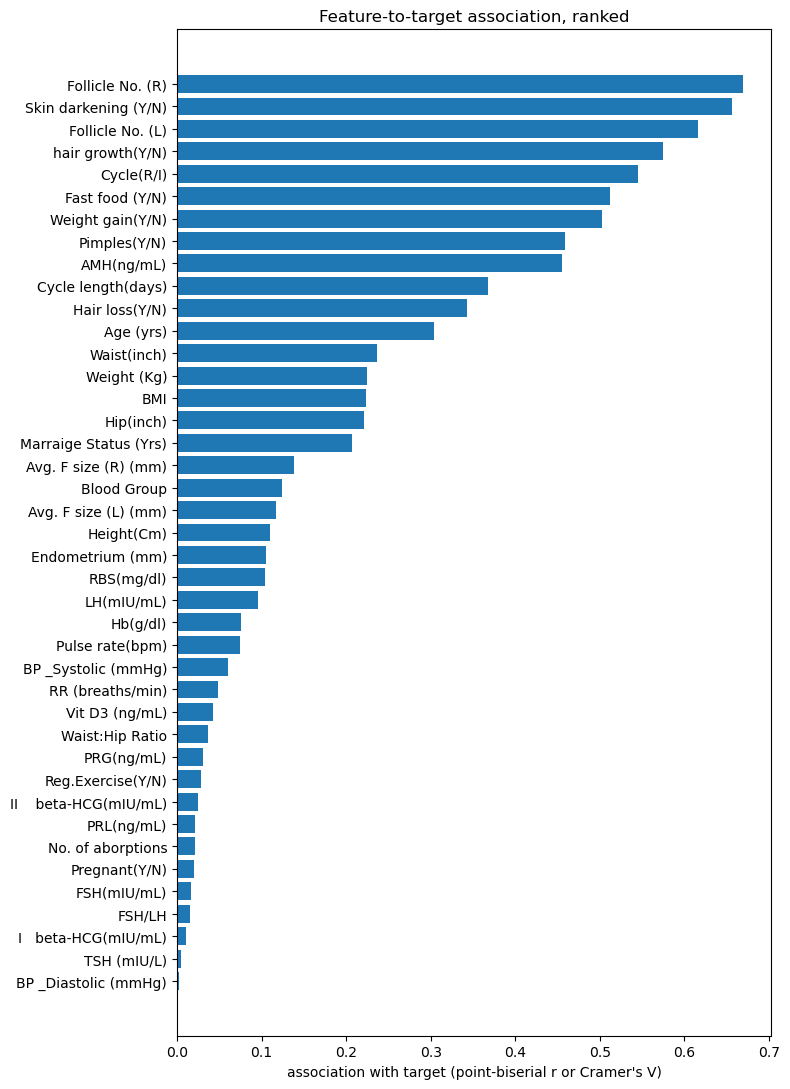

In [25]:
combined = pd.concat([
    num_vs_target[['feature', 'abs_r']].rename(columns={'abs_r': 'association'}),
    cat_vs_target[['feature', 'cramers_v']].rename(columns={'cramers_v': 'association'})
]).sort_values('association', ascending=False)

plt.figure(figsize=(8, 11))
plt.barh(combined['feature'], combined['association'])
plt.gca().invert_yaxis()
plt.xlabel('association with target (point-biserial r or Cramer\'s V)')
plt.title('Feature-to-target association, ranked')
plt.tight_layout()
plt.show()

This chart puts all features on roughly the same scale for ranking purposes only — a point-biserial r and a Cramér's V aren't the same statistic, so this is meant as a rough ranking, not an exact comparison.

In [26]:
X_vif = add_constant(df[continuous_cols])
vif = pd.DataFrame()
vif['feature'] = X_vif.columns
vif['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif = vif[vif['feature'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)
vif

,feature,VIF
0,FSH(mIU/mL),18.929190
1,FSH/LH,18.896340
2,Weight (Kg),2.488294
3,BMI,2.383154
4,Hip(inch),2.363338
5,Waist(inch),2.112798
6,Follicle No. (L),1.982447
7,Follicle No. (R),1.884323
8,Age (yrs),1.641824
9,Marraige Status (Yrs),1.562521



A handful of features have a VIF well above 10 — mostly the same ones flagged in the correlation heatmap
(`BMI`, `Waist:Hip Ratio`, `FSH/LH`). High VIF is a real problem for something like logistic regression
(unstable, hard-to-interpret coefficients), but Random Forest and XGBoost split on one feature at a time
so they're much less affected — the main downside there is that importance gets shared between correlated
features rather than showing up cleanly on one of them.


## 7. Multivariate Analysis

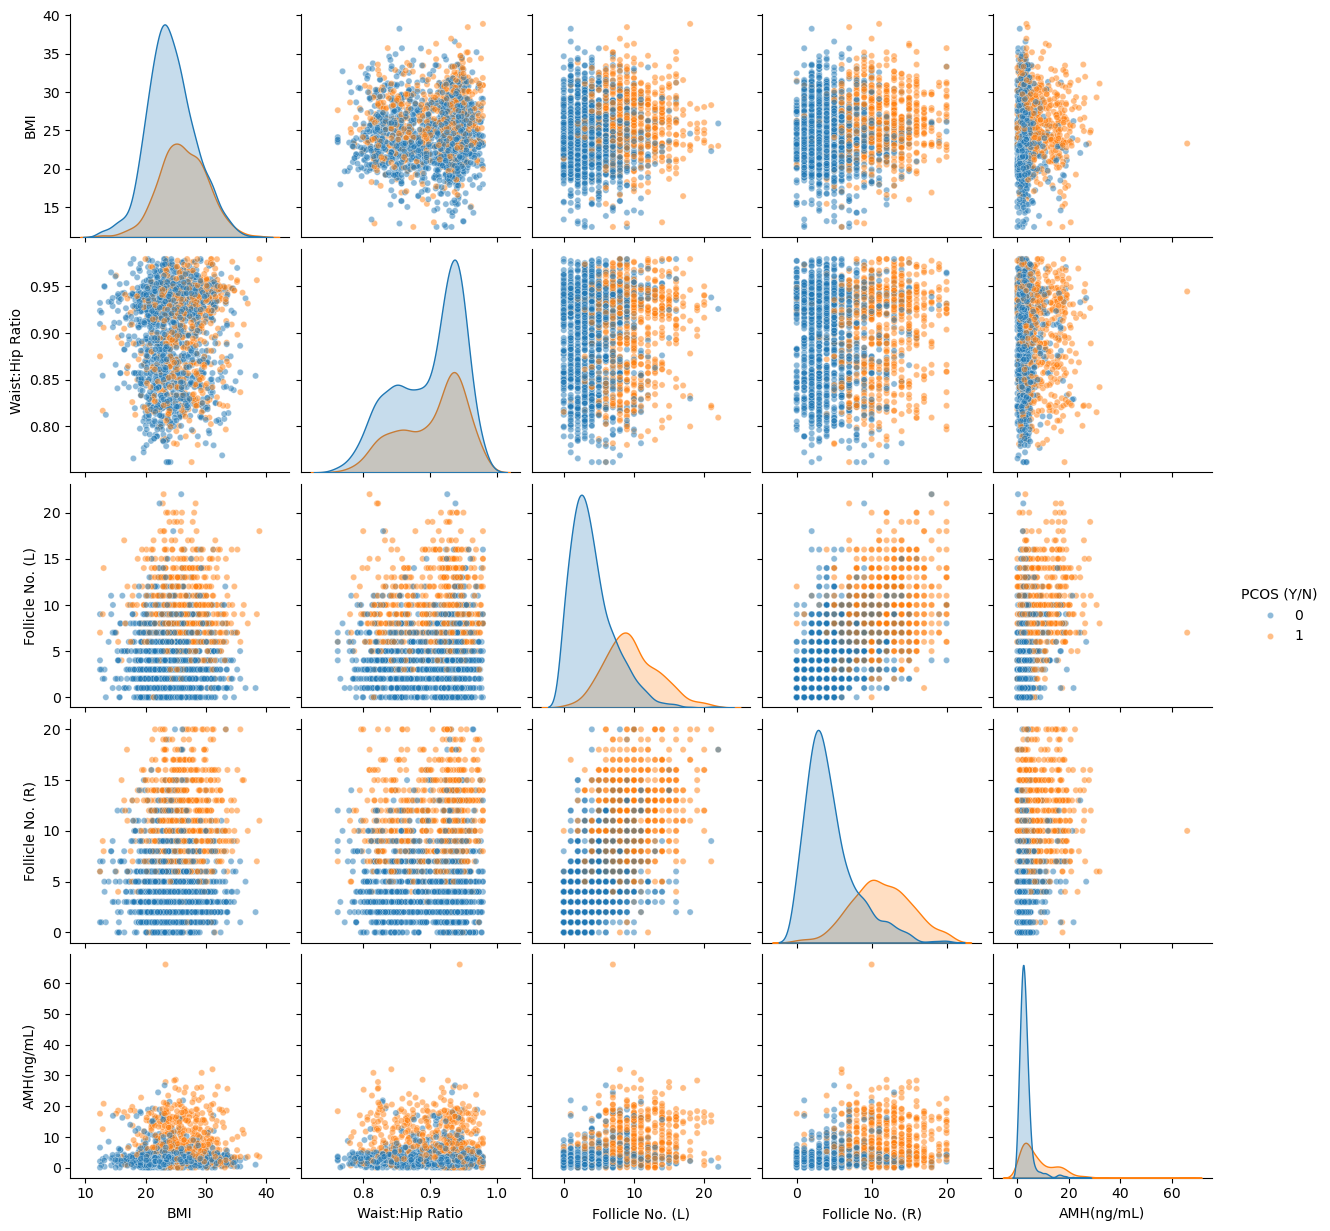

In [27]:
pairplot_cols = ['BMI', 'Waist:Hip Ratio', 'Follicle No. (L)', 'Follicle No. (R)', 'AMH(ng/mL)', target]
sns.pairplot(df[pairplot_cols], hue=target, diag_kind='kde', plot_kws={'alpha': 0.5, 's': 20})
plt.show()


`Follicle No. (L)` and `Follicle No. (R)` together separate the two groups more clearly than either does
by itself — PCOS patients tend to have a high follicle count on both sides at once, matching the clinical
picture of polycystic ovaries.


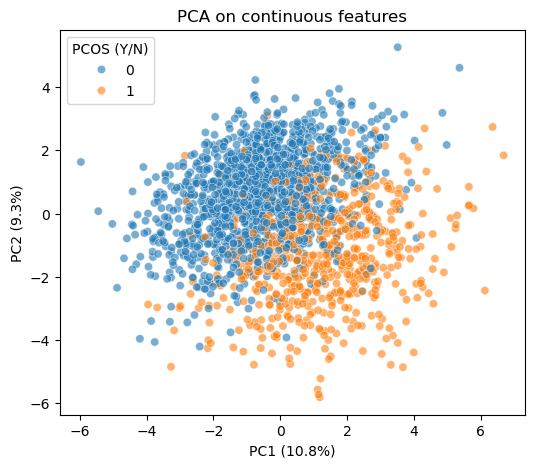

In [28]:
X_scaled = StandardScaler().fit_transform(df[continuous_cols])
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)

plt.figure(figsize=(6, 5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df[target], alpha=0.6)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('PCA on continuous features')
plt.show()


There's some separation between the two classes in the first two components but a lot of overlap too, so
this isn't a problem that a simple linear boundary would solve well. That's a point in favor of using
tree-based models, which can pick up non-linear splits and interactions between features.


## 8. Feature Importance

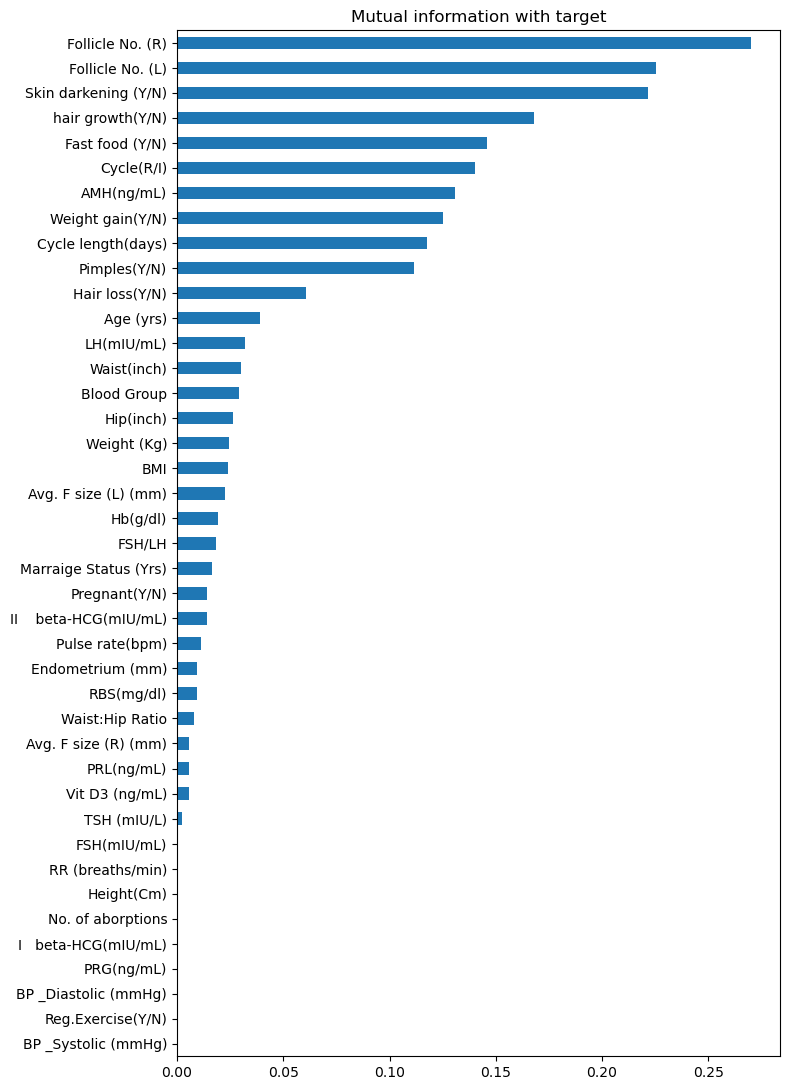

In [29]:
feature_cols = [c for c in df.columns if c != target]
X = df[feature_cols]
y = df[target]

mi = mutual_info_classif(X, y, random_state=RANDOM_STATE)
mi_scores = pd.Series(mi, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8, 11))
mi_scores.plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Mutual information with target')
plt.tight_layout()
plt.show()

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

rf = RandomForestClassifier(n_estimators=400, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
rf_auc = roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])

rf_importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

xgb_clf = xgb.XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
                             scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
                             eval_metric='logloss', random_state=RANDOM_STATE)
xgb_clf.fit(X_train, y_train)
xgb_auc = roc_auc_score(y_test, xgb_clf.predict_proba(X_test)[:, 1])

xgb_importance = pd.Series(xgb_clf.feature_importances_, index=feature_cols).sort_values(ascending=False)

print(f'RF test ROC-AUC: {rf_auc:.4f}   XGBoost test ROC-AUC: {xgb_auc:.4f}')

RF test ROC-AUC: 0.9887   XGBoost test ROC-AUC: 0.9874


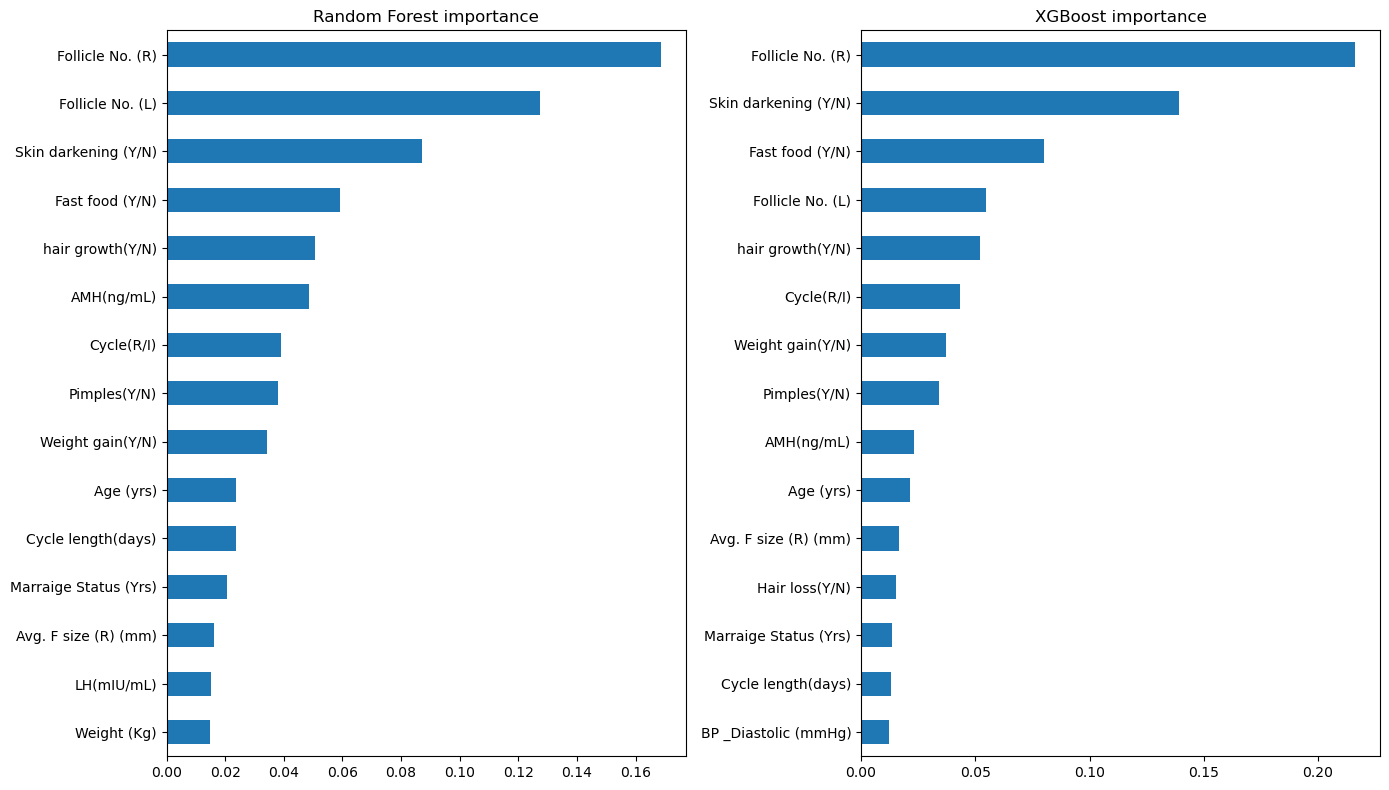

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
rf_importance.head(15)[::-1].plot(kind='barh', ax=axes[0], title='Random Forest importance')
xgb_importance.head(15)[::-1].plot(kind='barh', ax=axes[1], title='XGBoost importance')
plt.tight_layout()
plt.show()

These are baseline models just to rank features, not tuned final models. Both agree fairly well on which features matter most, and it roughly matches what showed up in the correlation analysis.

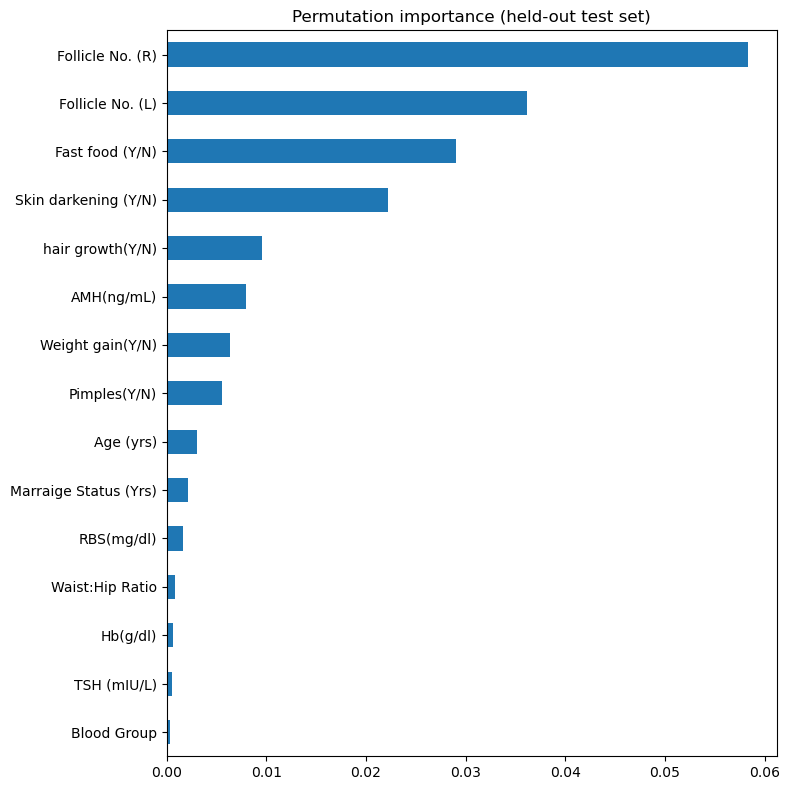

In [32]:
perm = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
perm_importance = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)

perm_importance.head(15)[::-1].plot(kind='barh', figsize=(8, 8))
plt.title('Permutation importance (held-out test set)')
plt.tight_layout()
plt.show()

Permutation importance is measured on the held-out test set rather than during training, so it's a useful cross-check against the built-in RF/XGBoost importances, which can be a bit biased when features are correlated.

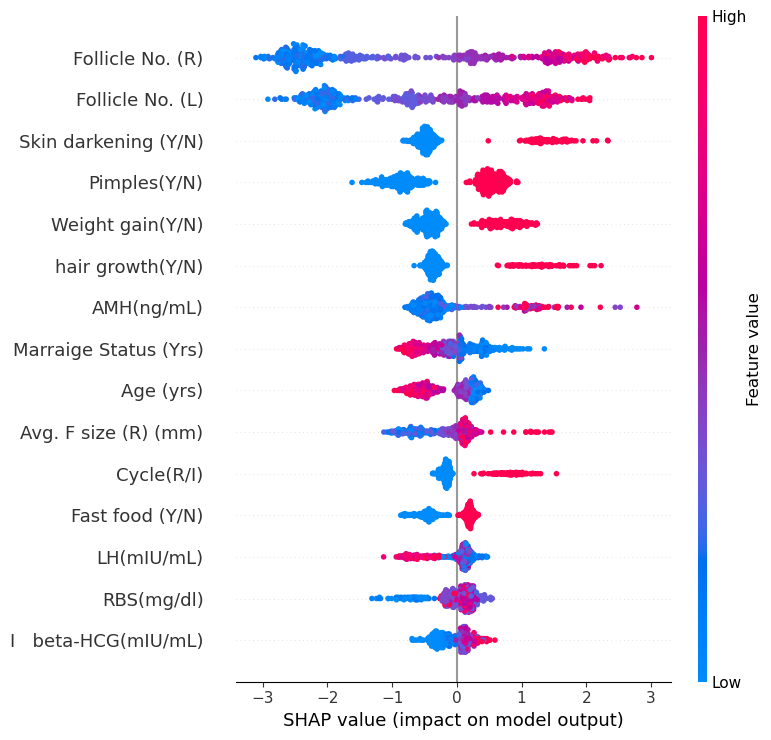

In [33]:
if SHAP_AVAILABLE:
    explainer = shap.TreeExplainer(xgb_clf)
    shap_values = explainer.shap_values(X_test)
    shap.summary_plot(shap_values, X_test, show=False, max_display=15)
    plt.tight_layout()
    plt.show()
else:
    print('shap is not installed in this environment, skipping this plot.')

The SHAP plot shows both how much each feature matters and which direction it pushes the prediction (e.g. higher follicle counts pushing toward a PCOS prediction), which is a bit more informative than just an importance score.

## 9. Bias and Leakage Check


None of the columns directly encode the target (there's no diagnosis code or treatment column), so there's
no obvious hard leakage. There is a softer issue though: several of the strongest features
(`Follicle No.`, `Skin darkening`, `hair growth`, `Weight gain`) are close to the actual criteria doctors
use to diagnose PCOS in the first place (the Rotterdam criteria cover hyperandrogenism symptoms and
polycystic ovarian morphology on ultrasound). That's not necessarily wrong to use for prediction, but it
means the model is partly learning the diagnostic rule rather than an independent biomarker, which is
worth being upfront about.


In [34]:
diagnostic_features = ['Follicle No. (L)', 'Follicle No. (R)', 'hair growth(Y/N)', 'Skin darkening (Y/N)',
                        'Weight gain(Y/N)', 'Cycle(R/I)']
X_diag_train, X_diag_test, y_diag_train, y_diag_test = train_test_split(
    df[diagnostic_features], y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
rf_diag = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE)
rf_diag.fit(X_diag_train, y_diag_train)
diag_auc = roc_auc_score(y_diag_test, rf_diag.predict_proba(X_diag_test)[:, 1])
print(f'ROC-AUC using only diagnostic-criteria-like features: {diag_auc:.4f}')
print(f'ROC-AUC using all features: {rf_auc:.4f}')

ROC-AUC using only diagnostic-criteria-like features: 0.9534
ROC-AUC using all features: 0.9887



Just those six features already get close to the full-feature-set performance, which confirms that most of
the model's predictive power is coming from features tied to the diagnostic criteria rather than from
independent lab values.

Other things worth noting:
- There's no patient ID column, so it's not possible to confirm each row is a different patient.
- `Blood Group` shows some association with the target in the chi-square test, but there's no known
  biological link between ABO blood type and PCOS, so this is more likely a coincidence in this sample
  than a real signal.
- The dataset doesn't say where or how patients were recruited, so it's hard to know how well a model
  built on this data would generalize elsewhere.


## 10. Feature Engineering

In [35]:
df_fe = df.copy()

df_fe['BMI_category'] = pd.cut(df_fe['BMI'], bins=[0, 18.5, 25, 30, 100],
                                labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

symptom_cols = ['Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)']
df_fe['Symptom_count'] = df_fe[symptom_cols].sum(axis=1)

df_fe['Total_follicle_count'] = df_fe['Follicle No. (L)'] + df_fe['Follicle No. (R)']
df_fe['Follicle_asymmetry'] = (df_fe['Follicle No. (L)'] - df_fe['Follicle No. (R)']).abs()

df_fe[['BMI_category', 'Symptom_count', 'Total_follicle_count', 'Follicle_asymmetry']].head()

,BMI_category,Symptom_count,Total_follicle_count,Follicle_asymmetry
0,Normal,0,14,8
1,Normal,0,5,1
2,Normal,0,3,3
3,Obese,2,17,9
4,Normal,2,11,1


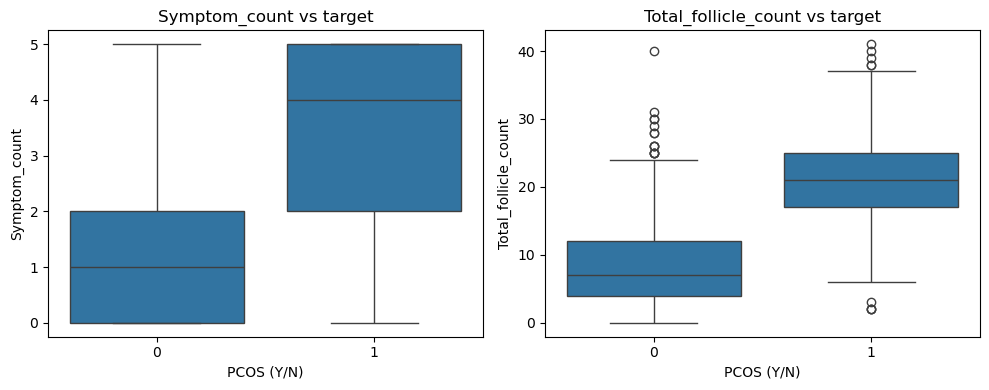

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(x=df_fe[target], y=df_fe['Symptom_count'], ax=axes[0])
sns.boxplot(x=df_fe[target], y=df_fe['Total_follicle_count'], ax=axes[1])
axes[0].set_title('Symptom_count vs target')
axes[1].set_title('Total_follicle_count vs target')
plt.tight_layout()
plt.show()


Both of these simple combined features separate the two groups pretty well, at least as well as the
individual columns they're built from. A few more ideas that make sense for this data but weren't built
out fully here: an age-group bucket, a cycle-length deviation from 28 days, and log-transforming the very
skewed hormone columns (`FSH/LH`, `AMH`, `PRL`, `TSH`, beta-HCG) if a linear model is used later — tree
models don't need this.

For encoding: the Y/N columns are already 0/1, `Blood Group` would need one-hot encoding for a linear
model (tree models can take the raw codes), and `BMI_category` can be ordinal-encoded since the categories
have a natural order.


## 11. Feature Ranking

In [37]:
rank = pd.concat([
    num_vs_target[['feature', 'abs_r']].rename(columns={'abs_r': 'association'}),
    cat_vs_target[['feature', 'cramers_v']].rename(columns={'cramers_v': 'association'})
], ignore_index=True)

rank = rank.merge(vif[['feature', 'VIF']], on='feature', how='left')
rank = rank.merge(rf_importance.rename('rf_importance'), left_on='feature', right_index=True, how='left')

def priority(row):
    if row['VIF'] > 10:
        return 'redundant / check before linear model'
    if row['association'] > 0.3:
        return 'strong'
    if row['association'] > 0.15:
        return 'moderate'
    return 'weak'

rank['priority'] = rank.apply(priority, axis=1)
rank = rank.sort_values('rf_importance', ascending=False).reset_index(drop=True)
rank.round(4)

,feature,association,VIF,rf_importance,priority
0,Follicle No. (R),0.6694,1.8843,0.1686,strong
1,Follicle No. (L),0.6165,1.9824,0.1273,strong
2,Skin darkening (Y/N),0.6557,NaN,0.0872,strong
3,Fast food (Y/N),0.5114,NaN,0.0591,strong
4,hair growth(Y/N),0.5749,NaN,0.0507,strong
5,AMH(ng/mL),0.4549,1.4050,0.0486,strong
6,Cycle(R/I),0.5453,NaN,0.0392,strong
7,Pimples(Y/N),0.4591,NaN,0.0379,strong
8,Weight gain(Y/N),0.5027,NaN,0.0343,strong
9,Age (yrs),0.3040,1.6418,0.0238,strong


In [38]:
rank['priority'].value_counts()

priority
weak                                     22
strong                                   12
moderate                                  5
redundant / check before linear model     2
Name: count, dtype: int64


`Blood Group` is left out of the "strong/moderate/weak" logic above on purpose — its association score
doesn't mean much given there's no clinical reason for it to matter, as discussed in the bias section.


## 12. Conclusion


**Features most associated with the target:** follicle counts (both sides), the hyperandrogenism symptoms
(`Skin darkening`, `hair growth`, `Weight gain`), `BMI`, `Waist:Hip Ratio`, and cycle regularity. This is
consistent across the correlation/Cramér's V numbers, mutual information, and both tree-based models, and
it also matches how PCOS is actually diagnosed clinically (Rotterdam criteria), which is reassuring — it
suggests the pattern is real rather than just noise in this particular sample.

**Weaker associations:** `Blood Group`, pulse rate, respiratory rate, and most of the vitals showed little
individual relationship with the target. That doesn't rule out them mattering in combination with other
features, but on their own they're low priority.

**Redundant features:** `Weight` and `BMI`, `Hip`/`Waist` and `Waist:Hip Ratio`, `FSH`/`LH` and `FSH/LH`,
and the two beta-HCG readings are all measuring overlapping things. Worth dropping one from each pair for
a linear model; fine to keep for Random Forest/XGBoost.

**Possible bias / leakage:** the follicle and symptom features overlap with the actual diagnostic criteria
for PCOS, so a chunk of the model's performance is coming from features that are close to the label itself
rather than independent biomarkers. There's also no patient ID to rule out repeated patients, and no
information about where the data was collected, so generalizing this model to a different population isn't
guaranteed.

**Recommended feature set:** for both Random Forest and XGBoost, the "strong" and "moderate" features from
the ranking table above are a reasonable starting point, keeping in mind the leakage caveat. `Blood Group`
is probably worth dropping unless there's a specific reason to keep testing it.

**Feature engineering worth trying:** `Symptom_count`, `Total_follicle_count`, `Follicle_asymmetry`, and
`BMI_category`, all of which showed reasonable separation between the groups above.

None of this shows that any feature *causes* PCOS — it just shows which features are associated with the
target in this dataset. Next step would be cleaning up the data-entry issues found in section 2, then
retraining and tuning the actual models with cross-validation.
